# Indonesian Coffee Retail Wars: SQL Database and Basket Analysis

**Applied Data Science project | SQLite + synthetic data + SQL + association rules + document-based NoSQL comparison**

**Research question:** How do fictitious coffee chains, products, locations, loyalty tiers and promotions relate to purchases and product bundles in a simulated Indonesian retail market?

> **Academic integrity and source declaration.** Every transactional, customer, store, chain and product record in this project is **synthetically generated by the Python code below**. We **do not download, import, transform or copy any Kaggle rows**, because the assignment explicitly prohibits using someone else's data. The [Kaggle topic page](https://www.kaggle.com/datasets/luthfimuthathohirin/indonesia-coffee-chain-wars-retail-market) is inspiration for the subject only. All store names and chain names in the generated dataset are fictional. No result should be interpreted as a statement about real Indonesian brands, prices or consumer behavior.

**Deliverables produced by executing all cells:**

1. `indonesia_coffee_wars_synthetic.sqlite` — the complete relational SQLite database.
2. `coffee_orders_documents.jsonl` — portable, denormalized order documents for a NoSQL-style demonstration.
3. Two analysis figures and printed database-quality checks, SQL results and association rules.

**Run:** Python 3.10+ with `numpy`, `pandas`, and `matplotlib` installed. The optional `mlxtend` / `tinydb` examples detect their own installation and skip gracefully. Execute cells **in order**; re-running the schema cell recreates the six project-owned tables in the named SQLite file. Do not point `DB_PATH` at an unrelated database.

## 1. Concept, data generation and measurement scales

This project models purchases made during 2025 at 20 fictitious coffee outlets in five Indonesian cities. The random seed makes the dataset reproducible. A weighted generator produces customer segments, store popularity, day/time variation, basket sizes, product prices, promotional discounts and several intentional beverage–pastry affinities. These are **assumptions of a simulation**, not estimates derived from external data.

| Measurement scale | Example attribute | Why it fits |
|:--|:--|:--|
| **Nominal** | `orders.sales_channel`, `stores.city` | Unordered names/classes. |
| **Ordinal** | `orders.queue_priority` (`Standard` → `Priority` → `VIP`); `customers.loyalty_tier` | Categories have a meaningful order, but the gaps are not numerically equal. |
| **Interval** | `orders.outdoor_temp_c` (°C) | Differences are meaningful, but zero °C does **not** mean no temperature; ratios are not meaningful. These temperatures are simulated, not measurements. |
| **Ratio** | `orders.party_size`, `order_items.quantity`, `order_items.unit_price_idr` | A true zero exists conceptually and multiplication/ratios make sense; constraints restrict stored sales to positive values. |

The `orders` table itself contains **10 columns** and more than **1,000 rows**, including the four required scales; `order_items` has a **compound primary key**.

### Relational schema (textual ERD)
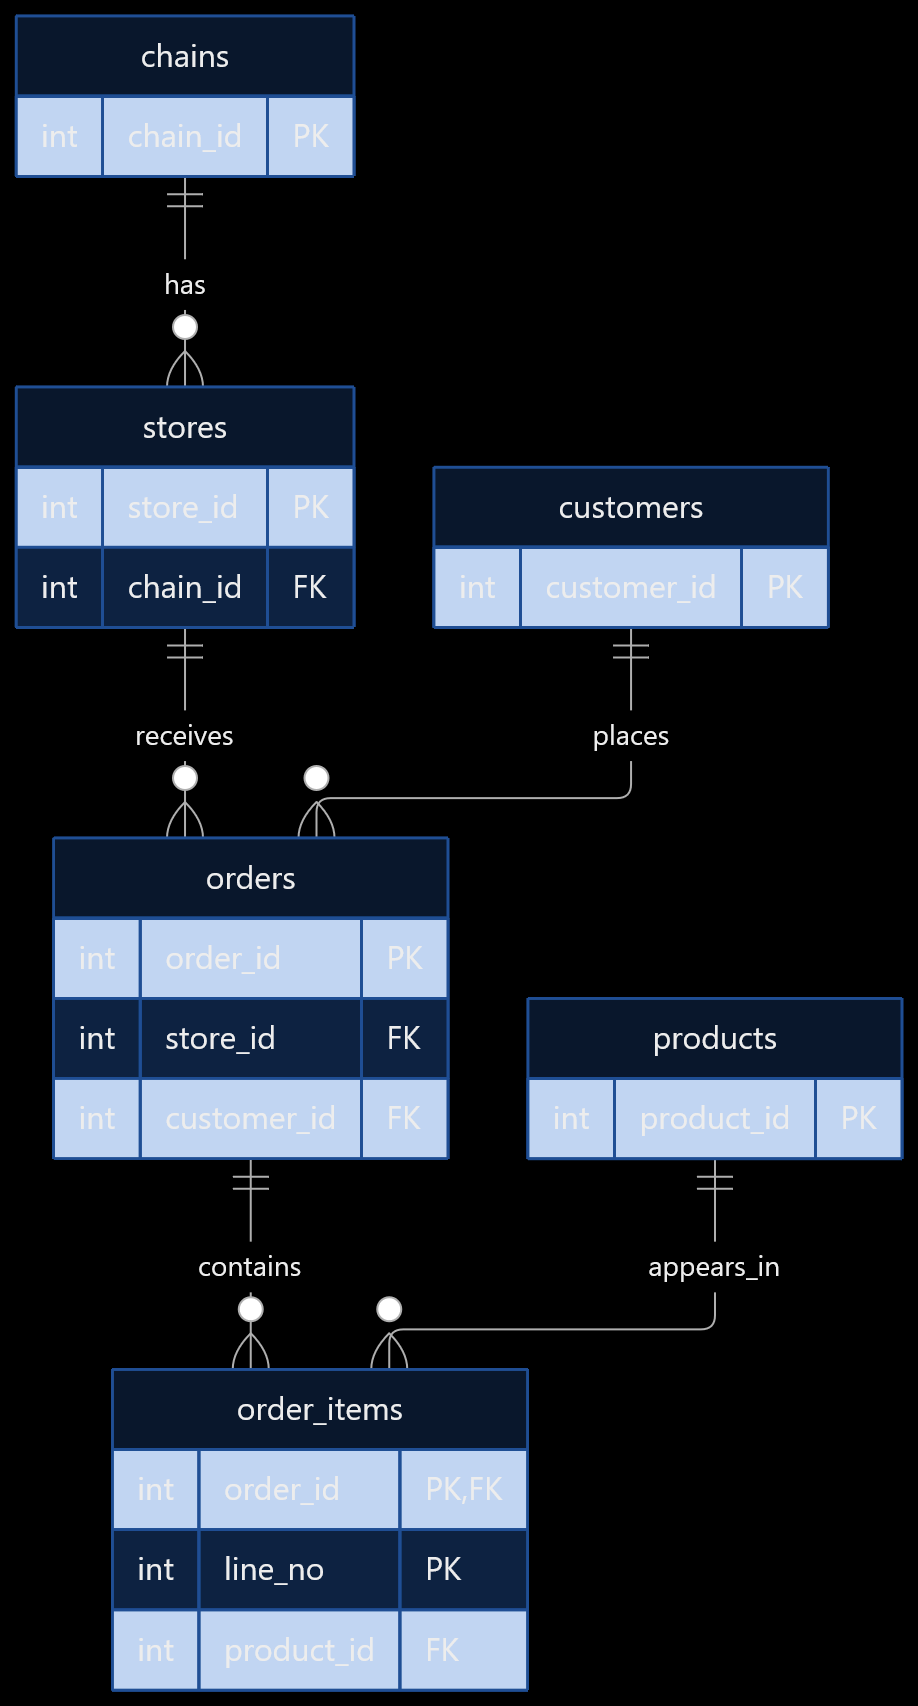


**Normalization / justification:** Chain details are stored once; stores refer to chains; customer segments are separate from individual orders; products and catalog prices are stored once; order items form a many-to-many bridge between orders and products. `unit_price_idr` is deliberately repeated in `order_items` to preserve **the historical price actually charged** if a catalog price later changes. `line_no` identifies each line within an order, so `(order_id, line_no)` is a natural compound key. All foreign keys and domain checks are enforced by SQLite.

**Privacy and ethics:** No real customers, addresses, telephone numbers, emails, loyalty IDs or sensitive data are used. Customer numbers are invented and not linked to people. There are no precise store addresses. Simulated temperatures, pricing, purchasing affinities and cities must not be presented as real observations or used for commercial decisions. In a real system, restrict access, minimize retained identifiers, specify retention periods, validate consent and treat loyalty segmentation carefully to prevent unfair targeting.

In [1]:
# 2. Imports and reproducibility. No dataset download is performed.
from collections import Counter, defaultdict
from datetime import datetime, timedelta
from itertools import combinations
from pathlib import Path
import json
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261105
RNG = np.random.default_rng(SEED)
N_ORDERS = 8_000
N_CUSTOMERS = 2_200

# Files are created next to the notebook when it is executed in Jupyter's folder.
DB_PATH = Path.cwd() / "indonesia_coffee_wars_synthetic.sqlite"
DOCUMENT_PATH = Path.cwd() / "coffee_orders_documents.jsonl"

print(f"Seed: {SEED:,}; planned orders: {N_ORDERS:,}; customers: {N_CUSTOMERS:,}")
print("SQLite output:", DB_PATH)

Seed: 20,261,105; planned orders: 8,000; customers: 2,200
SQLite output: /content/indonesia_coffee_wars_synthetic.sqlite


## 2. Create the normalized SQLite database

`CHECK` constraints implement domain rules; `NOT NULL` protects required fields; `UNIQUE` prevents duplicate labels; `FOREIGN KEY` maintains parent-child relationships. Per the [official SQLite foreign-key documentation](https://www.sqlite.org/foreignkeys.html), enforcement is explicitly enabled with `PRAGMA foreign_keys = ON` on every connection. `PRIMARY KEY (order_id, line_no)` is the compound key.

In [2]:
# Rebuild ONLY the six tables owned by this example in the named output file.
# This keeps the notebook repeatable. The database is not a live operational system.
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")
assert conn.execute("PRAGMA foreign_keys").fetchone()[0] == 1

schema_sql = """
DROP TABLE IF EXISTS order_items;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS customers;
DROP TABLE IF EXISTS stores;
DROP TABLE IF EXISTS chains;

CREATE TABLE chains (
    chain_id         INTEGER PRIMARY KEY,
    chain_name       TEXT NOT NULL UNIQUE,
    market_segment   TEXT NOT NULL CHECK (market_segment IN ('Value', 'Midrange', 'Premium'))
);

CREATE TABLE stores (
    store_id         INTEGER PRIMARY KEY,
    chain_id         INTEGER NOT NULL REFERENCES chains(chain_id),
    city             TEXT NOT NULL CHECK (city IN ('Jakarta','Bandung','Surabaya','Yogyakarta','Denpasar')),
    district_label   TEXT NOT NULL,
    store_format     TEXT NOT NULL CHECK (store_format IN ('Mall','High Street','Transit')),
    opened_year      INTEGER NOT NULL CHECK (opened_year BETWEEN 2015 AND 2025),
    UNIQUE (chain_id, city)
);

CREATE TABLE customers (
    customer_id      INTEGER PRIMARY KEY,
    home_city        TEXT NOT NULL,
    loyalty_tier     TEXT NOT NULL CHECK (loyalty_tier IN ('Bronze','Silver','Gold','Platinum')),
    age_band         TEXT NOT NULL CHECK (age_band IN ('18-24','25-34','35-44','45+')),
    joined_on        TEXT NOT NULL,
    marketing_opt_in INTEGER NOT NULL CHECK (marketing_opt_in IN (0,1))
);

CREATE TABLE products (
    product_id       INTEGER PRIMARY KEY,
    product_name     TEXT NOT NULL UNIQUE,
    category         TEXT NOT NULL CHECK (category IN ('Coffee','Non-Coffee','Pastry','Food')),
    serving_size     TEXT NOT NULL CHECK (serving_size IN ('Small','Medium','Large','Standard')),
    list_price_idr   INTEGER NOT NULL CHECK (list_price_idr > 0),
    unit_cost_idr    INTEGER NOT NULL CHECK (unit_cost_idr > 0 AND unit_cost_idr < list_price_idr),
    is_seasonal      INTEGER NOT NULL CHECK (is_seasonal IN (0,1))
);

CREATE TABLE orders (
    order_id         INTEGER PRIMARY KEY,
    store_id         INTEGER NOT NULL REFERENCES stores(store_id),
    customer_id      INTEGER REFERENCES customers(customer_id),  -- NULL means anonymous guest
    ordered_at       TEXT NOT NULL,                          -- ISO 8601 text; 2025 local simulation
    sales_channel    TEXT NOT NULL CHECK (sales_channel IN ('In-Store','Takeaway','Delivery')),
    payment_method   TEXT NOT NULL CHECK (payment_method IN ('Card','Cash','E-Wallet')),
    promotion_applied INTEGER NOT NULL CHECK (promotion_applied IN (0,1)),
    queue_priority   TEXT NOT NULL CHECK (queue_priority IN ('Standard','Priority','VIP')),
    outdoor_temp_c   REAL NOT NULL CHECK (outdoor_temp_c BETWEEN 18.0 AND 40.0),
    party_size       INTEGER NOT NULL CHECK (party_size BETWEEN 1 AND 6)
);

CREATE TABLE order_items (
    order_id         INTEGER NOT NULL REFERENCES orders(order_id) ON DELETE CASCADE,
    line_no          INTEGER NOT NULL CHECK (line_no >= 1),
    product_id       INTEGER NOT NULL REFERENCES products(product_id),
    quantity         INTEGER NOT NULL CHECK (quantity BETWEEN 1 AND 5),
    unit_price_idr   INTEGER NOT NULL CHECK (unit_price_idr > 0),
    discount_idr     INTEGER NOT NULL DEFAULT 0 CHECK (discount_idr >= 0),
    PRIMARY KEY (order_id, line_no),
    CHECK (discount_idr <= quantity * unit_price_idr)
);

CREATE INDEX idx_orders_store_date ON orders(store_id, ordered_at);
CREATE INDEX idx_orders_customer ON orders(customer_id);
CREATE INDEX idx_items_product ON order_items(product_id);
"""
conn.executescript(schema_sql)
conn.commit()
print("Created 6 normalized tables, foreign keys, checks and indexes.")

Created 6 normalized tables, foreign keys, checks and indexes.


## 3. Generate distinct, reproducible, realistic-looking synthetic records

**Generation logic:** Four fictional chains operate in each of five cities (20 stores). The catalog contains coffees, alternative drinks, pastries and food with plausible *illustrative* prices in Indonesian rupiah. Customers are allocated to cities and loyalty tiers by weighted random sampling. Orders are generated across 2025; store demand, hour of day, party size, payment method, baskets and promotions are randomized. Prices have a fictional chain multiplier; discounts cannot exceed gross line value.

To create an association-rule signal, selected coffee drinks have an intentionally higher probability of being ordered with particular pastries. This is a **simulation design choice** and is disclosed to avoid mistaking simulated affinity for discovered real-world behavior.

In [3]:
# Master data: deliberately invented entities and transparent assumptions.
chains = [
    (1, "Kopi Awan (fictional)", "Value"),
    (2, "Biji Kota (fictional)", "Midrange"),
    (3, "Ruang Rasa (fictional)", "Premium"),
    (4, "Senja Brew (fictional)", "Midrange"),
]

cities = ["Jakarta", "Bandung", "Surabaya", "Yogyakarta", "Denpasar"]
city_districts = {
    "Jakarta": "Central Zone", "Bandung": "North Zone", "Surabaya": "West Zone",
    "Yogyakarta": "University Zone", "Denpasar": "Coastal Zone",
}
city_temp_base = {"Jakarta": 30.0, "Bandung": 25.0, "Surabaya": 31.0,
                  "Yogyakarta": 29.0, "Denpasar": 29.5}
chain_price_multiplier = {1: 0.90, 2: 1.00, 3: 1.13, 4: 1.04}

stores = []
for chain_id in range(1, 5):
    for city_index, city in enumerate(cities):
        store_id = (chain_id - 1) * len(cities) + city_index + 1
        store_format = ["Mall", "High Street", "Transit"][(chain_id + city_index) % 3]
        stores.append((store_id, chain_id, city, city_districts[city],
                       store_format, 2018 + (chain_id + city_index) % 7))

# Name, category, size, illustrative list price in IDR.
catalog = [
    ("Iced Aren Latte M", "Coffee", "Medium", 28000),
    ("Iced Aren Latte L", "Coffee", "Large", 34000),
    ("Hot Cappuccino S", "Coffee", "Small", 26000),
    ("Hot Cappuccino M", "Coffee", "Medium", 31000),
    ("Iced Americano M", "Coffee", "Medium", 22000),
    ("Iced Americano L", "Coffee", "Large", 27000),
    ("Iced Vanilla Latte M", "Coffee", "Medium", 32000),
    ("Iced Vanilla Latte L", "Coffee", "Large", 38000),
    ("Cold Brew M", "Coffee", "Medium", 30000),
    ("Cold Brew L", "Coffee", "Large", 36000),
    ("Hot Espresso S", "Coffee", "Small", 18000),
    ("Matcha Latte M", "Non-Coffee", "Medium", 33000),
    ("Matcha Latte L", "Non-Coffee", "Large", 39000),
    ("Iced Chocolate M", "Non-Coffee", "Medium", 29000),
    ("Iced Chocolate L", "Non-Coffee", "Large", 35000),
    ("Butter Croissant", "Pastry", "Standard", 23000),
    ("Banana Bread", "Pastry", "Standard", 21000),
    ("Chocolate Muffin", "Pastry", "Standard", 22000),
    ("Cheese Danish", "Pastry", "Standard", 25000),
    ("Cinnamon Roll", "Pastry", "Standard", 24000),
    ("Almond Cookie", "Pastry", "Standard", 17000),
    ("Tuna Sandwich", "Food", "Standard", 41000),
    ("Chicken Wrap", "Food", "Standard", 44000),
]
products = []
for pid, (name, category, size, price) in enumerate(catalog, start=1):
    # Food cost is an invented fraction of list price, not an observed cost.
    cost = int(round(price * (0.38 if category in ("Coffee", "Non-Coffee") else 0.49) / 500) * 500)
    products.append((pid, name, category, size, price, cost, 0))

city_prob = [0.34, 0.21, 0.19, 0.13, 0.13]
loyalty_levels = ["Bronze", "Silver", "Gold", "Platinum"]
loyalty_prob = [0.49, 0.29, 0.17, 0.05]
age_bands = ["18-24", "25-34", "35-44", "45+"]
customers = []
for cid in range(1, N_CUSTOMERS + 1):
    city = str(RNG.choice(cities, p=city_prob))
    tier = str(RNG.choice(loyalty_levels, p=loyalty_prob))
    age_band = str(RNG.choice(age_bands, p=[0.26, 0.43, 0.22, 0.09]))
    joined_at = datetime(2023, 1, 1) + timedelta(days=int(RNG.integers(0, 730)))
    opt_in = int(RNG.random() < 0.48)
    customers.append((cid, city, tier, age_band, joined_at.date().isoformat(), opt_in))

with conn:  # commits together or rolls back if a constraint fails
    conn.executemany("INSERT INTO chains VALUES (?,?,?)", chains)
    conn.executemany("INSERT INTO stores VALUES (?,?,?,?,?,?)", stores)
    conn.executemany("INSERT INTO customers VALUES (?,?,?,?,?,?)", customers)
    conn.executemany("INSERT INTO products VALUES (?,?,?,?,?,?,?)", products)

print(f"Master records: {len(chains)} chains, {len(stores)} stores, "
      f"{len(customers):,} customers, {len(products)} products")

Master records: 4 chains, 20 stores, 2,200 customers, 23 products


In [4]:
# Simulate orders + line items. Historical transaction prices are retained.
store_by_id = {row[0]: row for row in stores}
customer_by_id = {row[0]: row for row in customers}
customers_by_city = defaultdict(list)
for cid, city, *_ in customers:
    customers_by_city[city].append(cid)

product_by_id = {row[0]: row for row in products}
product_id_by_name = {row[1]: row[0] for row in products}
product_ids = np.array([row[0] for row in products])
product_weights = np.array([
    0.160, 0.053, 0.047, 0.083, 0.075, 0.030, 0.052, 0.025,
    0.043, 0.018, 0.027, 0.060, 0.020, 0.040, 0.017, 0.048,
    0.041, 0.035, 0.032, 0.027, 0.021, 0.025, 0.022,
], dtype=float)
product_weights /= product_weights.sum()

special_pairs = {
    product_id_by_name["Iced Aren Latte M"]: product_id_by_name["Butter Croissant"],
    product_id_by_name["Hot Cappuccino M"]: product_id_by_name["Banana Bread"],
    product_id_by_name["Matcha Latte M"]: product_id_by_name["Cheese Danish"],
}
drinks = np.array([r[0] for r in products if r[2] in ("Coffee", "Non-Coffee")])
drink_weights = np.array([product_weights[pid - 1] for pid in drinks]); drink_weights /= drink_weights.sum()

store_weights = np.array([
    [0.36, 0.27, 0.21, 0.16][r[1] - 1] * city_prob[cities.index(r[2])]
    for r in stores
], dtype=float)
store_weights /= store_weights.sum()
store_ids = np.array([row[0] for row in stores])

hours = np.arange(7, 22)
hour_weights = np.array([2,4,5,4,7,8,7,5,4,5,7,8,7,5,3], dtype=float)
hour_weights /= hour_weights.sum()
start = datetime(2025, 1, 1)

order_rows, item_rows = [], []
for oid in range(1, N_ORDERS + 1):
    sid = int(RNG.choice(store_ids, p=store_weights))
    _, chain_id, city, *_ = store_by_id[sid]
    # ~23% of orders are guests, while most identified customers live locally.
    if RNG.random() < 0.23:
        customer_id = None
        tier = "Guest"
    else:
        pool = customers_by_city[city] if RNG.random() < 0.88 else list(customer_by_id)
        customer_id = int(RNG.choice(pool))
        tier = customer_by_id[customer_id][2]

    dt = start + timedelta(days=int(RNG.integers(0, 365)),
                           hours=int(RNG.choice(hours, p=hour_weights)),
                           minutes=int(RNG.integers(0, 60)))
    channel = str(RNG.choice(["In-Store","Takeaway","Delivery"], p=[0.46,0.35,0.19]))
    pay = str(RNG.choice(["E-Wallet","Card","Cash"], p=[0.61,0.25,0.14]))
    promo = int(RNG.random() < (0.29 if channel == "Delivery" else 0.16))
    priority = "VIP" if tier == "Platinum" else "Priority" if tier in ("Gold", "Silver") else "Standard"
    ambient = round(float(np.clip(RNG.normal(city_temp_base[city], 2.0), 19, 39)), 1)
    party_size = int(RNG.choice([1,2,3,4,5,6], p=[0.61,0.26,0.08,0.035,0.01,0.005]))
    order_rows.append((oid, sid, customer_id, dt.isoformat(sep=" ", timespec="seconds"),
                       channel, pay, promo, priority, ambient, party_size))

    basket_size = int(RNG.choice([1,2,3,4], p=[0.17,0.52,0.26,0.05]))
    first_id = int(RNG.choice(drinks, p=drink_weights)) if RNG.random() < 0.80 \
        else int(RNG.choice(product_ids, p=product_weights))
    basket = [first_id]
    # Inject plausible *synthetic* complementarity; never infer this about real buyers.
    if basket_size >= 2 and first_id in special_pairs and RNG.random() < 0.68:
        basket.append(special_pairs[first_id])
    while len(basket) < basket_size:
        pid = int(RNG.choice(product_ids, p=product_weights))
        if pid not in basket:
            basket.append(pid)

    for line_no, pid in enumerate(basket, start=1):
        _, _, cat, _, list_price, _, _ = product_by_id[pid]
        unit_price = int(round(list_price * chain_price_multiplier[chain_id] / 500) * 500)
        qty = 1 + int(RNG.random() < (0.075 if cat in ("Pastry", "Food") else 0.05))
        discount = int(round(unit_price * qty * (0.10 if promo else 0.00) / 500) * 500)
        item_rows.append((oid, line_no, pid, qty, unit_price, discount))

with conn:
    conn.executemany("INSERT INTO orders VALUES (?,?,?,?,?,?,?,?,?,?)", order_rows)
    conn.executemany("INSERT INTO order_items VALUES (?,?,?,?,?,?)", item_rows)

print(f"Generated {len(order_rows):,} orders and {len(item_rows):,} order-item rows")

Generated 8,000 orders and 17,593 order-item rows


## 4. Integrity tests and data dictionary

The following `assert` checks are assessment evidence: required row count, seven-or-more columns, at least one compound primary key, referential integrity, domain checks, nonnegative revenue, and zero orphaned line items. Running these tests is more reliable than merely asserting the schema is correct.

In [5]:
# Inspect all tables and confirm the core marking criteria.
counts = pd.read_sql_query("""
SELECT name AS table_name FROM sqlite_master
WHERE type = 'table' AND name NOT LIKE 'sqlite_%'
ORDER BY name
""", conn)
counts["rows"] = counts["table_name"].map(
    lambda name: conn.execute(f'SELECT COUNT(*) FROM "{name}"').fetchone()[0]
)
print(counts.to_string(index=False))

orders_columns = pd.read_sql_query("PRAGMA table_info(orders)", conn)
line_columns = pd.read_sql_query("PRAGMA table_info(order_items)", conn)
fk_violations = conn.execute("PRAGMA foreign_key_check").fetchall()
integrity = conn.execute("PRAGMA integrity_check").fetchone()[0]
orphan_count = conn.execute("""
 SELECT COUNT(*) FROM order_items i
 LEFT JOIN orders o ON o.order_id = i.order_id WHERE o.order_id IS NULL
""").fetchone()[0]
negative_lines = conn.execute("""
 SELECT COUNT(*) FROM order_items
 WHERE quantity * unit_price_idr - discount_idr < 0
""").fetchone()[0]

assert len(orders_columns) >= 7, "The orders table must have >=7 columns"
assert len(order_rows) >= 1000, "At least one table must contain >=1000 rows"
assert set(line_columns.loc[line_columns.pk > 0, "name"]) == {"order_id", "line_no"}
assert fk_violations == [], f"Foreign key problems: {fk_violations}"
assert integrity == "ok"
assert orphan_count == 0 and negative_lines == 0

print("\nPASS: 10 order columns; >=1,000 orders; composite PK; FK + integrity checks; positive net revenue")
print("\nOrders column names:", orders_columns["name"].tolist())
print("\nLine-item compound primary key:", line_columns.loc[line_columns.pk > 0, "name"].tolist())

 table_name  rows
     chains     4
  customers  2200
order_items 17593
     orders  8000
   products    23
     stores    20

PASS: 10 order columns; >=1,000 orders; composite PK; FK + integrity checks; positive net revenue

Orders column names: ['order_id', 'store_id', 'customer_id', 'ordered_at', 'sales_channel', 'payment_method', 'promotion_applied', 'queue_priority', 'outdoor_temp_c', 'party_size']

Line-item compound primary key: ['order_id', 'line_no']


In [6]:
# A SQL data dictionary, including declared type, nullable flag and key roles.
dictionary = []
for tablename in counts.table_name:
    for col in conn.execute(f'PRAGMA table_info("{tablename}")').fetchall():
        cid, name, datatype, notnull, default, pk_order = col
        dictionary.append({"table": tablename, "column": name, "sql_type": datatype,
                           "required": bool(notnull or pk_order), "pk_position": pk_order})
data_dictionary = pd.DataFrame(dictionary)
print(data_dictionary.to_string(index=False))

      table            column sql_type  required  pk_position
     chains          chain_id  INTEGER      True            1
     chains        chain_name     TEXT      True            0
     chains    market_segment     TEXT      True            0
  customers       customer_id  INTEGER      True            1
  customers         home_city     TEXT      True            0
  customers      loyalty_tier     TEXT      True            0
  customers          age_band     TEXT      True            0
  customers         joined_on     TEXT      True            0
  customers  marketing_opt_in  INTEGER      True            0
order_items          order_id  INTEGER      True            1
order_items           line_no  INTEGER      True            2
order_items        product_id  INTEGER      True            0
order_items          quantity  INTEGER      True            0
order_items    unit_price_idr  INTEGER      True            0
order_items      discount_idr  INTEGER      True            0
     ord

## 5. Retrieve information with SQL joins, aggregation and subqueries

These queries demonstrate extraction from a relational database. They join normalized tables, combine columns, filter by date and geography, rank results and calculate sales **after** discounts. Values are in **Indonesian rupiah (IDR)**. Results reflect the synthetic generator only.

In [7]:
# Join four tables to calculate revenue by fictional chain and city.
chain_city_sql = """
SELECT c.chain_name, s.city,
       COUNT(DISTINCT o.order_id) AS orders,
       SUM(i.quantity) AS units,
       SUM(i.quantity * i.unit_price_idr - i.discount_idr) AS net_revenue_idr,
       ROUND(1.0 * SUM(i.quantity * i.unit_price_idr - i.discount_idr)
             / COUNT(DISTINCT o.order_id), 0) AS avg_order_value_idr
FROM chains c
JOIN stores s ON s.chain_id = c.chain_id
JOIN orders o ON o.store_id = s.store_id
JOIN order_items i ON i.order_id = o.order_id
GROUP BY c.chain_id, s.city
ORDER BY net_revenue_idr DESC;
"""
chain_city = pd.read_sql_query(chain_city_sql, conn)
print(chain_city.head(12).to_string(index=False))

            chain_name       city  orders  units  net_revenue_idr  avg_order_value_idr
 Kopi Awan (fictional)    Jakarta     962   2266         56951000              59201.0
 Biji Kota (fictional)    Jakarta     691   1552         43152500              62449.0
Ruang Rasa (fictional)    Jakarta     556   1319         41415000              74487.0
 Kopi Awan (fictional)    Bandung     600   1387         34627500              57713.0
 Kopi Awan (fictional)   Surabaya     568   1339         33310500              58645.0
 Biji Kota (fictional)    Bandung     487   1149         32047000              65805.0
Senja Brew (fictional)    Jakarta     438   1009         29421500              67172.0
 Biji Kota (fictional)   Surabaya     440   1023         28584500              64965.0
Ruang Rasa (fictional)    Bandung     362    839         26550000              73343.0
 Kopi Awan (fictional) Yogyakarta     419    941         23354500              55739.0
Ruang Rasa (fictional)   Surabaya     309  

In [8]:
# Top-selling products: group by product, then order by net revenue.
product_performance = pd.read_sql_query("""
SELECT p.product_name, p.category,
       SUM(i.quantity) AS units_sold,
       COUNT(DISTINCT i.order_id) AS baskets_containing_product,
       SUM(i.quantity * i.unit_price_idr - i.discount_idr) AS net_revenue_idr
FROM order_items i
JOIN products p ON p.product_id = i.product_id
GROUP BY p.product_id
ORDER BY net_revenue_idr DESC
LIMIT 12;
""", conn)
print(product_performance.to_string(index=False))

        product_name   category  units_sold  baskets_containing_product  net_revenue_idr
   Iced Aren Latte M     Coffee        2901                        2759         79190000
    Hot Cappuccino M     Coffee        1571                        1502         47693500
      Matcha Latte M Non-Coffee        1148                        1103         37058000
   Iced Aren Latte L     Coffee        1024                         986         34127500
    Butter Croissant     Pastry        1419                        1320         31787000
Iced Vanilla Latte M     Coffee        1002                         953         31333500
    Iced Americano M     Coffee        1399                        1319         30282500
         Cold Brew M     Coffee         788                         749         23160500
    Hot Cappuccino S     Coffee         870                         833         22211500
    Iced Chocolate M Non-Coffee         723                         690         20649500
        Banana Bread 

In [9]:
# Revenue over time and subquery for customers whose order count exceeds 5.
monthly = pd.read_sql_query("""
SELECT strftime('%Y-%m', o.ordered_at) AS sale_month,
       COUNT(DISTINCT o.order_id) AS orders,
       SUM(i.quantity * i.unit_price_idr - i.discount_idr) AS net_revenue_idr
FROM orders o JOIN order_items i ON i.order_id = o.order_id
GROUP BY sale_month ORDER BY sale_month;
""", conn)

repeat_customers = pd.read_sql_query("""
SELECT c.loyalty_tier, COUNT(*) AS customers_with_more_than_5_orders
FROM customers c
WHERE c.customer_id IN (
    SELECT customer_id FROM orders
    WHERE customer_id IS NOT NULL
    GROUP BY customer_id HAVING COUNT(*) > 5
)
GROUP BY c.loyalty_tier
ORDER BY customers_with_more_than_5_orders DESC;
""", conn)

print("MONTHLY REVENUE\n", monthly.to_string(index=False))
print("\nREPEAT CUSTOMER COUNTS\n", repeat_customers.to_string(index=False))

MONTHLY REVENUE
 sale_month  orders  net_revenue_idr
   2025-01     669         43749000
   2025-02     626         39514500
   2025-03     648         42251000
   2025-04     669         43807500
   2025-05     652         42563000
   2025-06     622         40193000
   2025-07     724         46307000
   2025-08     719         46197000
   2025-09     655         42258000
   2025-10     660         42212000
   2025-11     700         44623500
   2025-12     656         41382000

REPEAT CUSTOMER COUNTS
 loyalty_tier  customers_with_more_than_5_orders
      Bronze                                 74
      Silver                                 39
        Gold                                 29
    Platinum                                 13


## 6. Prepare database data for onward processing

Join transactional and reference data into an analysis-ready frame; parse dates; convert ordinal categories to explicitly ordered values; calculate net line revenue; check missingness; and form **one set of distinct products per order** for association mining. Avoid using individual line quantities as separate baskets: the basket unit of analysis is the **order**.

In [10]:
analysis_df = pd.read_sql_query("""
SELECT o.order_id, o.ordered_at, o.sales_channel, o.queue_priority,
       o.outdoor_temp_c, o.party_size, o.promotion_applied,
       s.city, c.chain_name, p.product_name, p.category,
       i.quantity, i.unit_price_idr, i.discount_idr,
       cu.loyalty_tier
FROM orders o
JOIN stores s ON s.store_id = o.store_id
JOIN chains c ON c.chain_id = s.chain_id
JOIN order_items i ON i.order_id = o.order_id
JOIN products p ON p.product_id = i.product_id
LEFT JOIN customers cu ON cu.customer_id = o.customer_id
""", conn)

analysis_df["ordered_at"] = pd.to_datetime(analysis_df["ordered_at"])
analysis_df["month"] = analysis_df["ordered_at"].dt.to_period("M").astype(str)
analysis_df["day_of_week"] = analysis_df["ordered_at"].dt.day_name()
analysis_df["net_revenue_idr"] = (
    analysis_df["quantity"] * analysis_df["unit_price_idr"] - analysis_df["discount_idr"]
)

analysis_df["queue_priority"] = pd.Categorical(
    analysis_df["queue_priority"], categories=["Standard", "Priority", "VIP"], ordered=True
)
analysis_df["loyalty_tier"] = pd.Categorical(
    analysis_df["loyalty_tier"], categories=["Bronze", "Silver", "Gold", "Platinum"], ordered=True
)

print("Joined data shape:", analysis_df.shape)
print("Missing customer tier is expected for guest checkouts:", int(analysis_df.loyalty_tier.isna().sum()))
print("Net revenue total (IDR):", int(analysis_df.net_revenue_idr.sum()))
print("\nPreview:\n", analysis_df.head(5).to_string(index=False))

Joined data shape: (17593, 18)
Missing customer tier is expected for guest checkouts: 3952
Net revenue total (IDR): 515057500

Preview:
  order_id          ordered_at sales_channel queue_priority  outdoor_temp_c  party_size  promotion_applied     city             chain_name         product_name   category  quantity  unit_price_idr  discount_idr loyalty_tier   month day_of_week  net_revenue_idr
        1 2025-11-09 14:27:00      In-Store       Standard            26.5           1                  1  Jakarta Ruang Rasa (fictional)         Banana Bread     Pastry         1           23500          2500       Bronze 2025-11      Sunday            21000
        1 2025-11-09 14:27:00      In-Store       Standard            26.5           1                  1  Jakarta Ruang Rasa (fictional)          Cold Brew M     Coffee         1           34000          3500       Bronze 2025-11      Sunday            30500
        1 2025-11-09 14:27:00      In-Store       Standard            26.5         

## 7. Market-basket association rules: support, confidence and lift

An itemset is a group of products in the same order. **Support** = share of all orders containing the full itemset. **Confidence** = share of orders containing antecedent A that also contain consequent B. **Lift** = confidence(A → B) / support(B): a lift over 1 indicates positive co-occurrence relative to independence, **not causation**.

The core implementation below uses standard Python (`Counter` + `itertools`) and needs no extra packages. It counts itemsets up to length 3, applies minimum support/confidence, and sorts rules by lift. It works offline. A subsequent optional cell demonstrates `mlxtend` FP-Growth and handles old/new `association_rules` signatures.

In [11]:
# Each order is exactly one basket of unique product names.
basket_rows = pd.read_sql_query("""
SELECT DISTINCT i.order_id, p.product_name
FROM order_items i JOIN products p ON p.product_id = i.product_id
ORDER BY i.order_id, p.product_name
""", conn)
baskets = basket_rows.groupby("order_id")["product_name"].apply(list).tolist()
assert len(baskets) == N_ORDERS

min_support = 0.012        # At least 1.2% of baskets
min_confidence = 0.12     # At least 12% conditional co-purchase
max_itemset_size = 3
support_counts = Counter()
for basket in baskets:
    unique_items = sorted(set(basket))
    for k in range(1, min(max_itemset_size, len(unique_items)) + 1):
        support_counts.update(combinations(unique_items, k))

n_baskets = len(baskets)
frequent = {items: count / n_baskets for items, count in support_counts.items()
            if count / n_baskets >= min_support}

rule_records = []
for itemset, support_ab in frequent.items():
    if len(itemset) < 2:
        continue
    for left_size in range(1, len(itemset)):
        for antecedent in combinations(itemset, left_size):
            consequent = tuple(sorted(set(itemset) - set(antecedent)))
            support_a = support_counts[tuple(sorted(antecedent))] / n_baskets
            support_b = support_counts[consequent] / n_baskets
            confidence = support_ab / support_a
            lift = confidence / support_b
            if confidence >= min_confidence:
                rule_records.append({
                    "antecedent": " + ".join(antecedent),
                    "consequent": " + ".join(consequent),
                    "support": support_ab,
                    "confidence": confidence,
                    "lift": lift,
                    "cooccurrence_orders": support_counts[itemset],
                })

rules = pd.DataFrame(rule_records)
if not rules.empty:
    rules = rules.sort_values(["lift", "support"], ascending=False).reset_index(drop=True)
    print(rules.head(15).round(3).to_string(index=False))
    print("\nInterpretation (synthetic only):")
    best = rules.iloc[0]
    print(f"{best['antecedent']} -> {best['consequent']}: "
          f"confidence={best['confidence']:.1%}; lift={best['lift']:.2f}.")
else:
    print("No rules met the thresholds; adjust the simulation or thresholds explicitly.")

          antecedent        consequent  support  confidence  lift  cooccurrence_orders
       Cheese Danish    Matcha Latte M    0.048       0.571 4.138                  388
      Matcha Latte M     Cheese Danish    0.048       0.352 4.138                  388
        Banana Bread  Hot Cappuccino M    0.067       0.607 3.231                  538
    Hot Cappuccino M      Banana Bread    0.067       0.358 3.231                  538
    Butter Croissant Iced Aren Latte M    0.124       0.755 2.188                  996
   Iced Aren Latte M  Butter Croissant    0.124       0.361 2.188                  996
         Cold Brew M  Iced Americano M    0.012       0.134 0.810                  100
   Iced Aren Latte L  Iced Americano M    0.016       0.129 0.781                  127
      Matcha Latte L Iced Aren Latte M    0.012       0.263 0.762                   97
    Hot Cappuccino S  Iced Americano M    0.013       0.122 0.743                  102
    Iced Americano L Iced Aren Latte M    0

## 8. Comparison with a document-oriented NoSQL model

SQLite is relational: normalized tables and SQL `JOIN`s reduce repetition and enforce referential integrity. A **document database** can store one order with its nested line items, often simplifying whole-order reads at the expense of repeating product/store labels and requiring application-level consistency. A JSONL file by itself is **not** a NoSQL database engine; it is a portable representation of the documents. The optional `tinydb` cell below writes/query these documents in a real lightweight document database if that package is installed. This distinction matters for a careful assessment.

The export excludes customer IDs and personal attributes. It includes the fictional chain/city, order timestamp, channel, and product-level sales only. Do not load untrusted user documents without validation in production.

In [12]:
# Convert SQL rows to nested, NoSQL-style JSON documents (one per order).
order_headers = pd.read_sql_query("""
SELECT o.order_id, o.ordered_at, o.sales_channel,
       o.promotion_applied, o.queue_priority, s.city, c.chain_name
FROM orders o
JOIN stores s ON s.store_id = o.store_id
JOIN chains c ON c.chain_id = s.chain_id
ORDER BY o.order_id
""", conn)

line_details = pd.read_sql_query("""
SELECT i.order_id, p.product_name, i.quantity,
       i.unit_price_idr, i.discount_idr,
       i.quantity * i.unit_price_idr - i.discount_idr AS net_revenue_idr
FROM order_items i JOIN products p ON p.product_id = i.product_id
ORDER BY i.order_id, i.line_no
""", conn)
lines_by_order = defaultdict(list)
for row in line_details.to_dict(orient="records"):
    oid = int(row.pop("order_id"))
    lines_by_order[oid].append(row)

order_documents = []
for header in order_headers.to_dict(orient="records"):
    oid = int(header["order_id"])
    header["items"] = lines_by_order[oid]
    header["order_total_idr"] = sum(line["net_revenue_idr"] for line in header["items"])
    order_documents.append(header)

with DOCUMENT_PATH.open("w", encoding="utf-8") as f:
    for document in order_documents:
        f.write(json.dumps(document, ensure_ascii=False) + "\n")

print(f"Exported {len(order_documents):,} JSONL order documents to {DOCUMENT_PATH.name}")
print("Example nested order:")
print(json.dumps(order_documents[0], indent=2, ensure_ascii=False))

Exported 8,000 JSONL order documents to coffee_orders_documents.jsonl
Example nested order:
{
  "order_id": 1,
  "ordered_at": "2025-11-09 14:27:00",
  "sales_channel": "In-Store",
  "promotion_applied": 1,
  "queue_priority": "Standard",
  "city": "Jakarta",
  "chain_name": "Ruang Rasa (fictional)",
  "items": [
    {
      "product_name": "Banana Bread",
      "quantity": 1,
      "unit_price_idr": 23500,
      "discount_idr": 2500,
      "net_revenue_idr": 21000
    },
    {
      "product_name": "Cold Brew M",
      "quantity": 1,
      "unit_price_idr": 34000,
      "discount_idr": 3500,
      "net_revenue_idr": 30500
    },
    {
      "product_name": "Iced Vanilla Latte L",
      "quantity": 1,
      "unit_price_idr": 43000,
      "discount_idr": 4500,
      "net_revenue_idr": 38500
    }
  ],
  "order_total_idr": 90000
}


In [14]:
# A NoSQL-style document retrieval and filter, followed by an optional TinyDB query.
# Query one document by its key and filter by nested attributes in ordinary Python.
order_by_id = {doc["order_id"]: doc for doc in order_documents}
print("Direct key lookup for order 42:", order_by_id[42]["order_total_idr"], "IDR")
matches = [doc for doc in order_documents
           if doc["city"] == "Bandung" and
           any(line["product_name"] == "Butter Croissant" for line in doc["items"])]
print("Bandung orders containing Butter Croissant:", len(matches))

try:
    !pip install tinydb -q
    from tinydb import TinyDB, Query
    document_db_path = Path.cwd() / "coffee_orders_tinydb.json"
    document_db = TinyDB(document_db_path)
    document_db.truncate()  # Only this demonstration's TinyDB file.
    document_db.insert_multiple(order_documents)
    Q = Query()
    found = document_db.search(Q.city == "Bandung")
    print(f"TinyDB document query (city = Bandung): {len(found):,} matches")
    document_db.close()
except ImportError:
    print("TinyDB is optional and not installed. To enable this engine: %pip install tinydb")

Direct key lookup for order 42: 60000 IDR
Bandung orders containing Butter Croissant: 294
TinyDB document query (city = Bandung): 1,716 matches


## 9. Visualize the synthetic market

The visualizations are descriptive and summarize invented data, not external observations. The charts are saved as images; each is reproducible from the generated SQLite data.

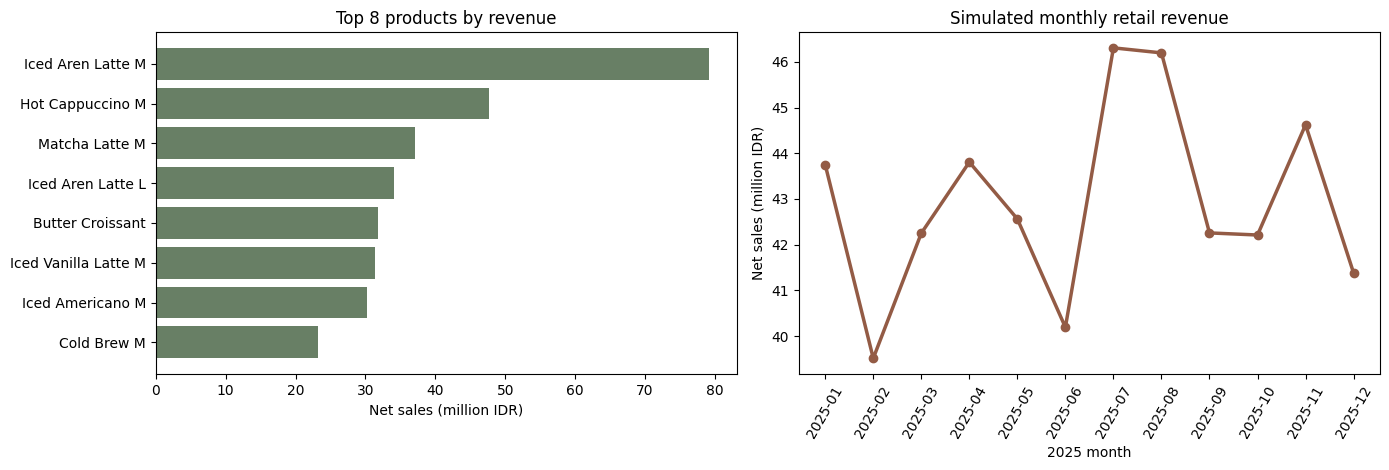

Chart saved to: coffee_market_summary.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
top = product_performance.head(8).sort_values("net_revenue_idr")
axes[0].barh(top["product_name"], top["net_revenue_idr"] / 1_000_000,
             color="#687f65")
axes[0].set_xlabel("Net sales (million IDR)")
axes[0].set_title("Top 8 products by revenue")

axes[1].plot(monthly["sale_month"], monthly["net_revenue_idr"] / 1_000_000,
             color="#935b45", linewidth=2.5, marker="o")
axes[1].set_xlabel("2025 month")
axes[1].set_ylabel("Net sales (million IDR)")
axes[1].set_title("Simulated monthly retail revenue")
axes[1].tick_params(axis="x", rotation=60)
fig.tight_layout()
figure_path = Path.cwd() / "coffee_market_summary.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print("Chart saved to:", figure_path.name)

## 10. Submission summary
**Limitations:** Results cannot validate Indonesia's real coffee chains, actual purchasing preferences or temperature-driven demand. Observed lift is partly caused by deliberate simulation rules and is not causal evidence. A stronger follow-up would stress-test the generator, compare cohorts, add timestamp-aware price tables, and report rule uncertainty on a separate sample.

In [17]:
# Final source-of-truth checks after analysis and document export.
assert conn.execute("PRAGMA foreign_key_check").fetchall() == []
assert conn.execute("SELECT COUNT(*) FROM orders").fetchone()[0] == N_ORDERS
assert conn.execute("SELECT COUNT(*) FROM order_items").fetchone()[0] == len(item_rows)
assert len(order_documents) == N_ORDERS
assert sum(d["order_total_idr"] for d in order_documents) == int(analysis_df.net_revenue_idr.sum())
print("All final checks passed: relational rows, documents and revenue agree.")
print("Database:", DB_PATH.name, f"({DB_PATH.stat().st_size / 1024**2:.2f} MiB)")
print("JSONL:", DOCUMENT_PATH.name, f"({DOCUMENT_PATH.stat().st_size / 1024**2:.2f} MiB)")
conn.close()

All final checks passed: relational rows, documents and revenue agree.
Database: indonesia_coffee_wars_synthetic.sqlite (1.69 MiB)
JSONL: coffee_orders_documents.jsonl (3.86 MiB)
